# Comparativa de modelos y elección final

Este notebook **no entrena nada**. Entrenar es trabajo de `python main.py`; aquí solo se
leen los resultados que dejó en `outputs/` y se cuentan.

Por qué separado: si el notebook entrenara por su cuenta tendrías dos verdades —la del
pipeline y la del notebook— y en la defensa te preguntarán cuál es la buena.

> Requisito: haber ejecutado antes `python main.py` (o `python main.py --demo`).

In [1]:
import sys, pathlib

# Subir hasta la raiz del proyecto (la carpeta que contiene src/), la abras desde donde la abras.
raiz = next(d for d in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (d / "src").is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

## 1. La tabla comparativa

Las seis filas con el mismo protocolo: mismo `StratifiedKFold`, misma semilla, el
preprocesado dentro del `Pipeline` y `scoring` fijado a la métrica principal.

In [2]:
tabla = pd.read_csv(config.OUTPUTS / "tabla_comparativa.csv")
display(tabla)
print(tabla.to_markdown(index=False))  # para pegarla en el apartado 7 del README

,modelo,f1,f1_std,accuracy,accuracy_std,precision,precision_std,recall,recall_std,roc_auc,roc_auc_std,tiempo_s
0,boosting,0.685600,0.009839,0.837927,0.004797,0.738966,0.009321,0.639436,0.010431,0.899984,0.004841,17.122144
1,red_keras,0.665876,0.013364,0.831270,0.003873,0.735164,0.004700,0.608972,0.023084,0.890362,0.004536,99.293165
2,bosque,0.654319,0.006763,0.833120,0.003373,0.765320,0.008663,0.571444,0.005734,0.894684,0.004997,39.093786
3,arbol,0.637246,0.005665,0.816105,0.003703,0.701225,0.015927,0.584567,0.015846,0.869429,0.005904,4.790222
4,logistica,0.541781,0.006822,0.785937,0.002852,0.663324,0.007444,0.457914,0.007298,0.830728,0.004252,6.387224
5,baseline,0.000000,0.000000,0.723619,0.000026,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,4.050836


| modelo    |       f1 |     f1_std |   accuracy |   accuracy_std |   precision |   precision_std |   recall |   recall_std |   roc_auc |   roc_auc_std |   tiempo_s |
|:----------|---------:|-----------:|-----------:|---------------:|------------:|----------------:|---------:|-------------:|----------:|--------------:|-----------:|
| boosting  | 0.6856   | 0.00983917 |   0.837927 |    0.00479697  |    0.738966 |      0.00932145 | 0.639436 |   0.0104305  |  0.899984 |    0.00484085 |   17.1221  |
| red_keras | 0.665876 | 0.0133636  |   0.83127  |    0.00387299  |    0.735164 |      0.00469995 | 0.608972 |   0.0230843  |  0.890362 |    0.00453581 |   99.2932  |
| bosque    | 0.654319 | 0.00676277 |   0.83312  |    0.00337272  |    0.76532  |      0.00866301 | 0.571444 |   0.0057343  |  0.894684 |    0.00499717 |   39.0938  |
| arbol     | 0.637246 | 0.00566532 |   0.816105 |    0.0037029   |    0.701225 |      0.0159267  | 0.584567 |   0.0158456  |  0.869429 |    0.00590431 |    4.79022 

## 2. Por qué el baseline no es decorativo

`DummyClassifier` es la línea del suelo. Sin ella, un F1 de 0,80 no dice si tu modelo
aprendió algo o si el problema era fácil.

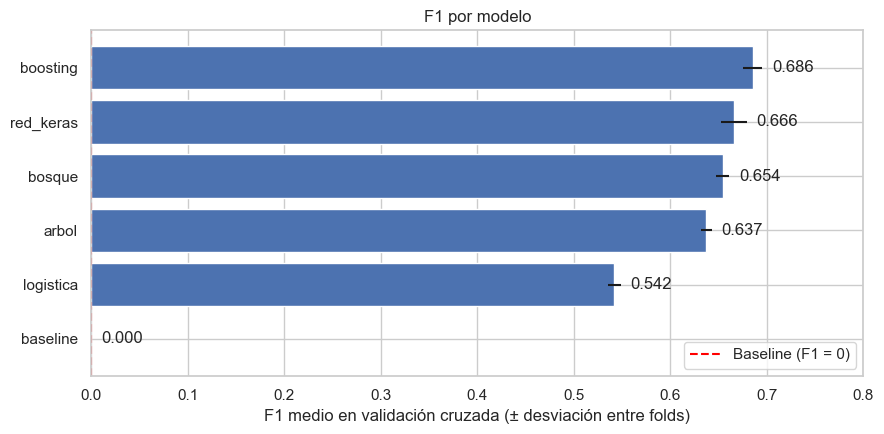

In [3]:
ordenada = tabla.sort_values("f1", ascending=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(ordenada["modelo"], ordenada["f1"], xerr=ordenada["f1_std"], color="#4C72B0")
ax.axvline(tabla.loc[tabla["modelo"] == "baseline", "f1"].iloc[0],
           color="red", linestyle="--", label="Baseline (F1 = 0)")
for y, (f1, sd) in enumerate(zip(ordenada["f1"], ordenada["f1_std"])):
    ax.text(f1 + sd + 0.01, y, f"{f1:.3f}", va="center")
ax.set_xlim(0, 0.8)
ax.set_xlabel("F1 medio en validación cruzada (± desviación entre folds)")
ax.set_title("F1 por modelo")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 3. Las tres figuras obligatorias

Ya las generó `evaluator.py`. Aquí se muestran juntas para poder narrarlas del tirón.

-- confusion_matrix.png --


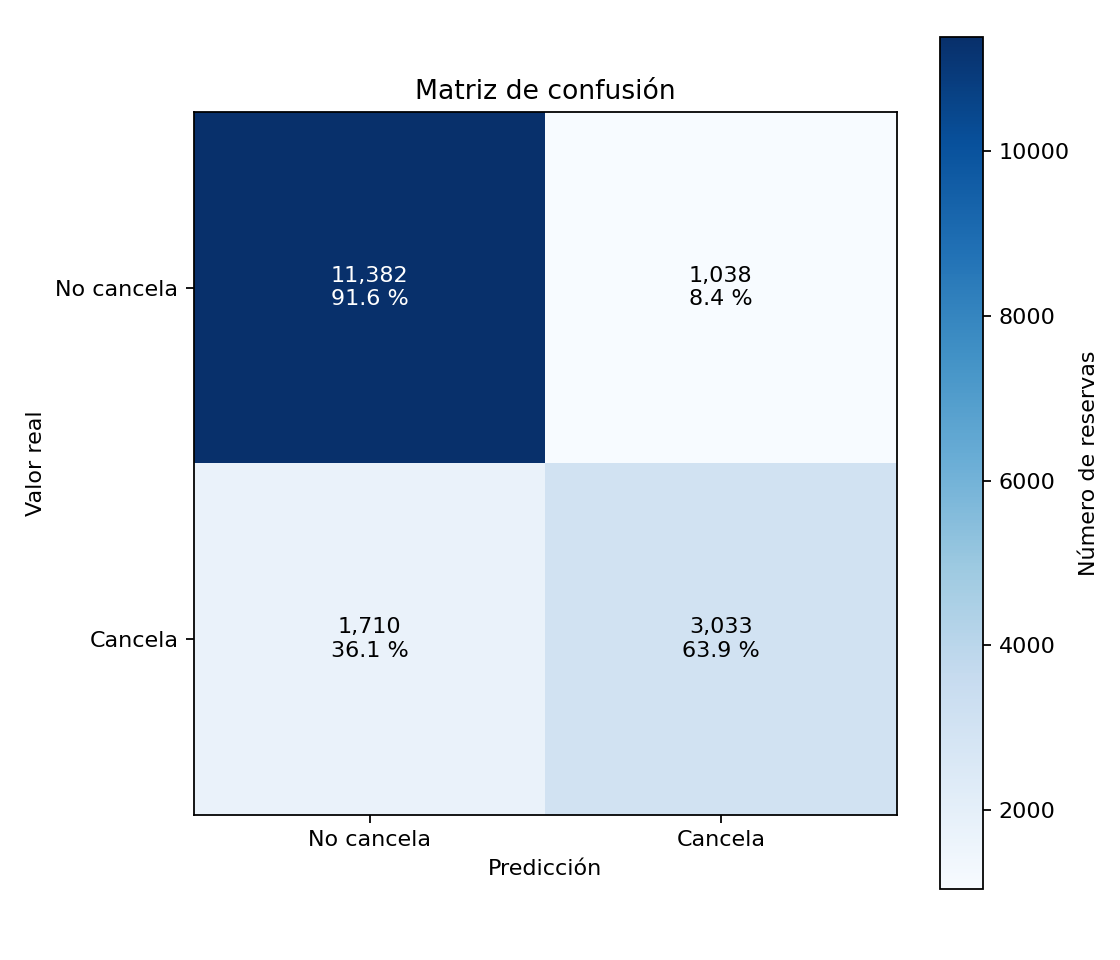

-- roc_curve.png --


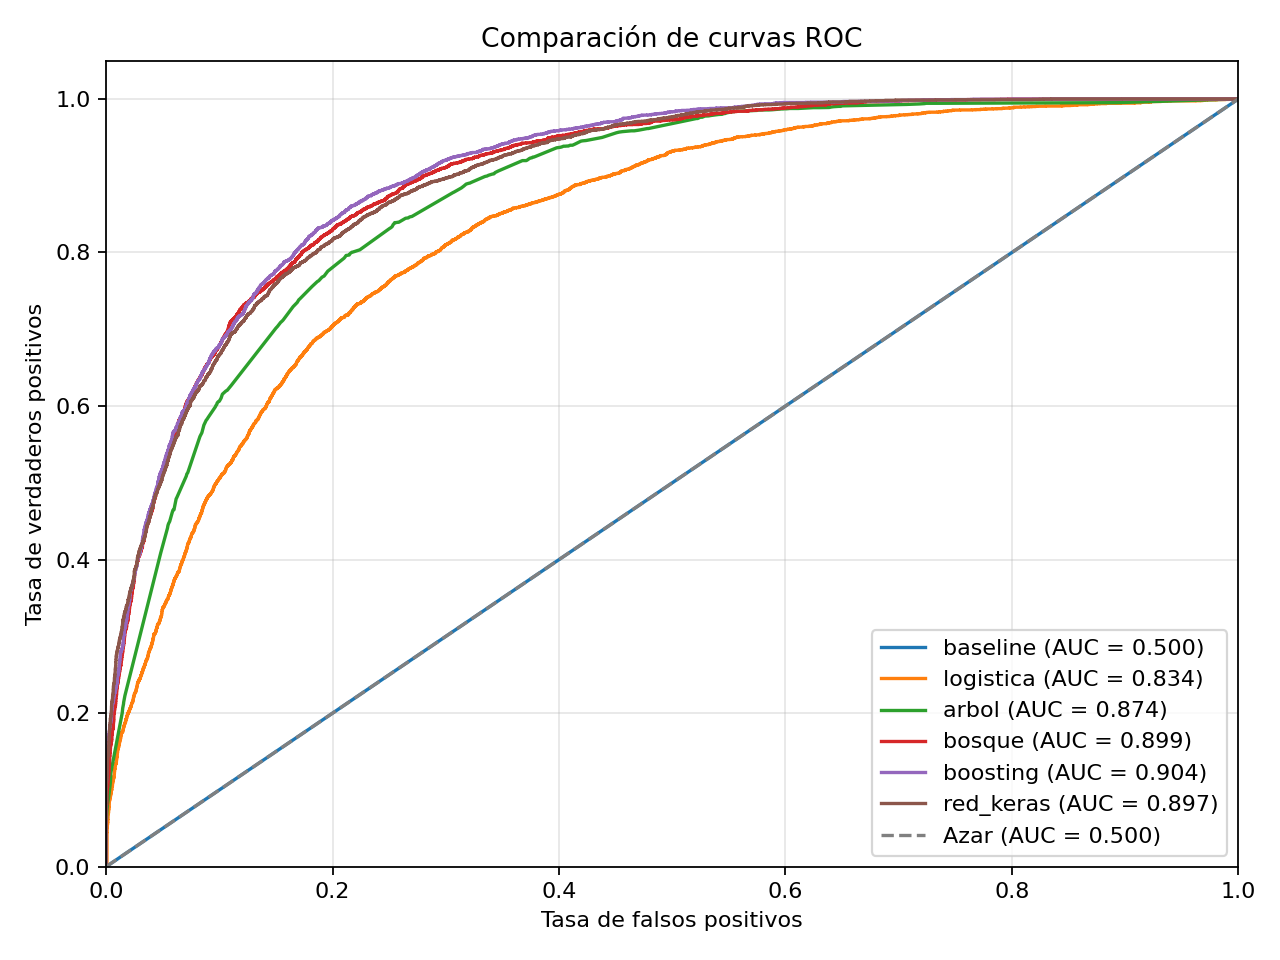

-- feature_importance.png --


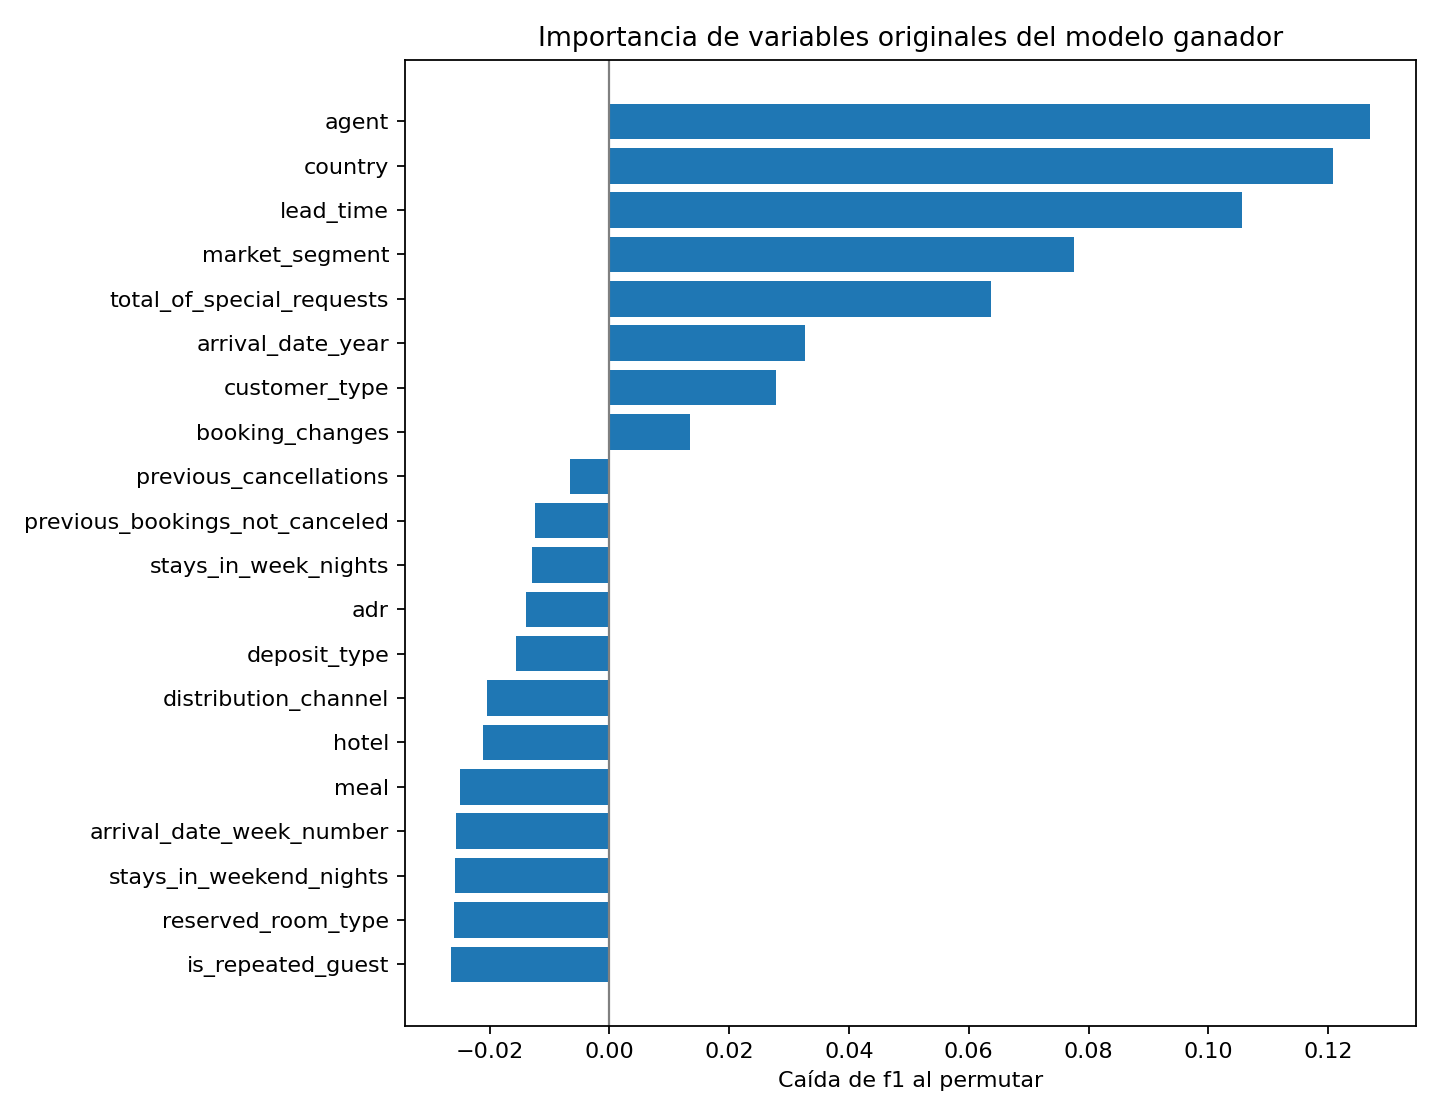

In [4]:
from IPython.display import Image, display as mostrar

for nombre in ["confusion_matrix.png", "roc_curve.png", "feature_importance.png"]:
    ruta = config.OUTPUTS / nombre
    print(f"-- {nombre} --")
    if ruta.exists():
        mostrar(Image(str(ruta)))
    else:
        print("   falta: ejecuta antes python main.py")

## 4. El ganador sobre el test

Medido **una sola vez**, al final. Cada vez que el test influye en una decisión deja de
ser una estimación honesta.

In [5]:
import json

metricas = json.loads((config.OUTPUTS / "metricas_test.json").read_text(encoding="utf-8"))
display(pd.Series(metricas).to_frame("valor"))

,valor
accuracy,0.839888
precision,0.745026
recall,0.639469
f1,0.688223
roc_auc,0.903686


## 5. Lectura: por qué gana este y no otro

**Modelo elegido:** XGBoost (`boosting`).

**Por qué gana:**

- **Mejor F1 en validación cruzada:** 0,6856 ± 0,0098, por delante de la red Keras
  (0,6659 ± 0,0134) y del Random Forest (0,6543 ± 0,0068). La diferencia con la red es
  mayor que la desviación entre folds de cualquiera de los dos: no es ruido.
- **Más recall sin hundir la precision:** 0,64 de recall frente a 0,57 del bosque. En este
  negocio el falso negativo es la habitación que se queda vacía sin que nadie lo vea
  venir, así que detectar más cancelaciones es justo lo que interesa.
- **Coste razonable:** entrena en 17 s, frente a los 99 s de la red, que además rinde menos.
- **CV y test coinciden:** F1 de 0,6882 en test frente a 0,6856 en CV. El test no sale
  sospechosamente mejor, así que la estimación es creíble.

**Lo que no resuelve:** con umbral 0,5 se le escapan unas 1.710 de las ~4.744
cancelaciones del test (recall 0,64). Mover el umbral pediría conocer el coste en euros
de cada error, que el dataset no trae.